In [3]:
import torch
from torch import nn
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch:", torch.__version__)
print("device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch: 2.14.1+cu130
device: cuda
GPU: NVIDIA GeForce RTX 2050


In [4]:
tf = transforms.Compose([
    transforms.Lambda(lambda img: TF.hflip(TF.rotate(img, -90))),  # sửa hướng ảnh EMNIST
    transforms.ToTensor(),
    transforms.Normalize((0.1736,), (0.3317,)),
])

train_full = datasets.EMNIST("../data", split="balanced", train=True,  download=True, transform=tf)
test_set   = datasets.EMNIST("../data", split="balanced", train=False, download=True, transform=tf)

print("train:", len(train_full), "| test:", len(test_set))
img, label = train_full[0]
print("shape:", img.shape, "| label:", label)

100.0%


train: 112800 | test: 18800
shape: torch.Size([1, 28, 28]) | label: 45


In [6]:
classes = list("0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabdefghnqrt")
print(len(classes))        # phải ra 47
print(classes[label])      # ký tự của ảnh đầu tiên

47
r


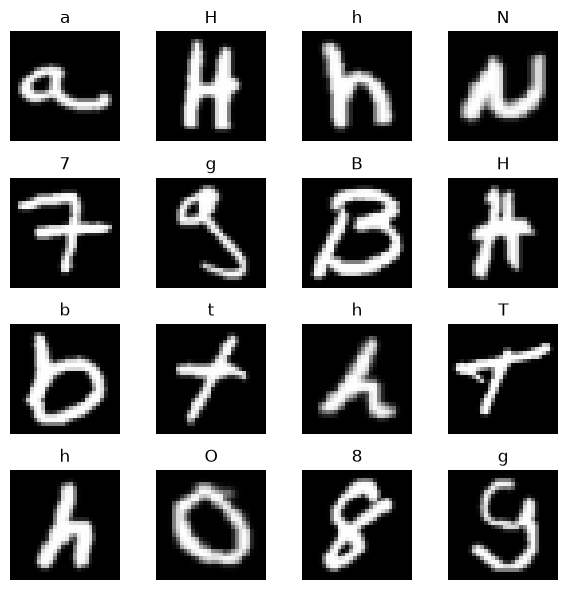

In [7]:
import random

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax in axes.flat:
    i = random.randrange(len(train_full))
    img, lab = train_full[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(classes[lab])
    ax.axis("off")
plt.tight_layout()
plt.show()

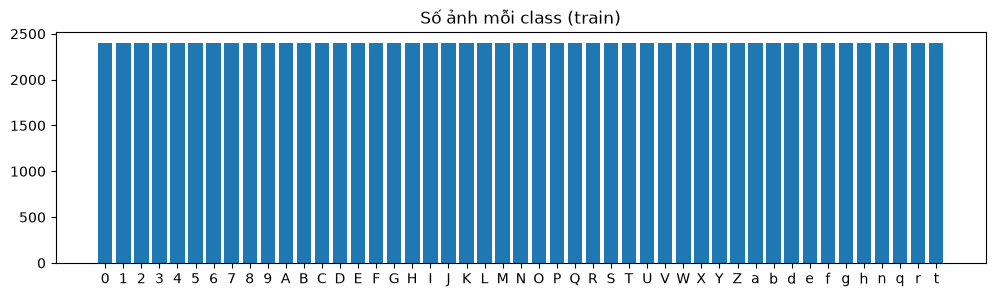

In [8]:
from collections import Counter

counts = Counter(train_full.targets.tolist())
plt.figure(figsize=(12, 3))
plt.bar([classes[k] for k in sorted(counts)], [counts[k] for k in sorted(counts)])
plt.title("Số ảnh mỗi class (train)")
plt.show()